In [1]:
from ultralytics import YOLO
from pathlib import Path

project_path = Path(r"E:\AI_ML PROJECTS\Helmet Detection")
model_path = project_path / "models" / "best.pt"

model = YOLO(str(model_path))

print("Model loaded successfully!")

Model loaded successfully!


In [2]:
data_yaml = project_path / "data" / "cleaned" / "helmet_dataset_cleaned" / "data.yaml"

print("Data YAML:", data_yaml)

Data YAML: E:\AI_ML PROJECTS\Helmet Detection\data\cleaned\helmet_dataset_cleaned\data.yaml


In [3]:
print("Data YAML exists:", data_yaml.exists())

Data YAML exists: True


In [4]:
metrics = model.val(
    data=str(data_yaml),
    split="test",
    imgsz=640,
    batch=8,
    device="cpu",
    plots=True,
    project=str(project_path / "results" / "evaluation"),
    name="test_evaluation",
    exist_ok=True
)

Ultralytics 8.4.149  Python-3.13.12 torch-2.14.0+cpu CPU (11th Gen Intel Core i5-1135G7 @ 2.40GHz)
Model summary (fused): 72 layers, 3,006,428 parameters, 0 gradients, 8.1 GFLOPs
WARNING val: Slow image access detected (ping: 21.913.7 ms, read: 1.60.8 MB/s, size: 61.6 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning E:\AI_ML PROJECTS\Helmet Detection\data\cleaned\helmet_dataset_cleaned\test\labels.cache... 847 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 847/847 86.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 106/106 1.3s/it 2:180.9ss
                   all        847       4458      0.922      0.897       0.95      0.703
                helmet        651       1781      0.923      0.877      0.933      0.656
             no_helmet        424        816      0.913      0.839       0.92      0.637
    

In [5]:
print("Overall Test Performance")
print("-" * 30)

print(f"Precision : {metrics.box.mp:.3f}")
print(f"Recall    : {metrics.box.mr:.3f}")
print(f"mAP50     : {metrics.box.map50:.3f}")
print(f"mAP50-95  : {metrics.box.map:.3f}")

Overall Test Performance
------------------------------
Precision : 0.922
Recall    : 0.897
mAP50     : 0.950
mAP50-95  : 0.703


In [6]:
names = model.names

print("Class-wise Performance")
print("-" * 60)

for i, name in names.items():
    print(f"{name:15s} | "
          f"Precision: {metrics.box.p[i]:.3f} | "
          f"Recall: {metrics.box.r[i]:.3f} | "
          f"mAP50: {metrics.box.ap50[i]:.3f} | "
          f"mAP50-95: {metrics.box.ap[i]:.3f}")

Class-wise Performance
------------------------------------------------------------
helmet          | Precision: 0.923 | Recall: 0.877 | mAP50: 0.933 | mAP50-95: 0.656
no_helmet       | Precision: 0.913 | Recall: 0.839 | mAP50: 0.920 | mAP50-95: 0.637
number_plate    | Precision: 0.955 | Recall: 0.949 | mAP50: 0.976 | mAP50-95: 0.715
rider           | Precision: 0.895 | Recall: 0.922 | mAP50: 0.969 | mAP50-95: 0.805


In [7]:
evaluation_path = project_path / "results" / "evaluation" / "test_evaluation"

print("Evaluation results:", evaluation_path)

Evaluation results: E:\AI_ML PROJECTS\Helmet Detection\results\evaluation\test_evaluation


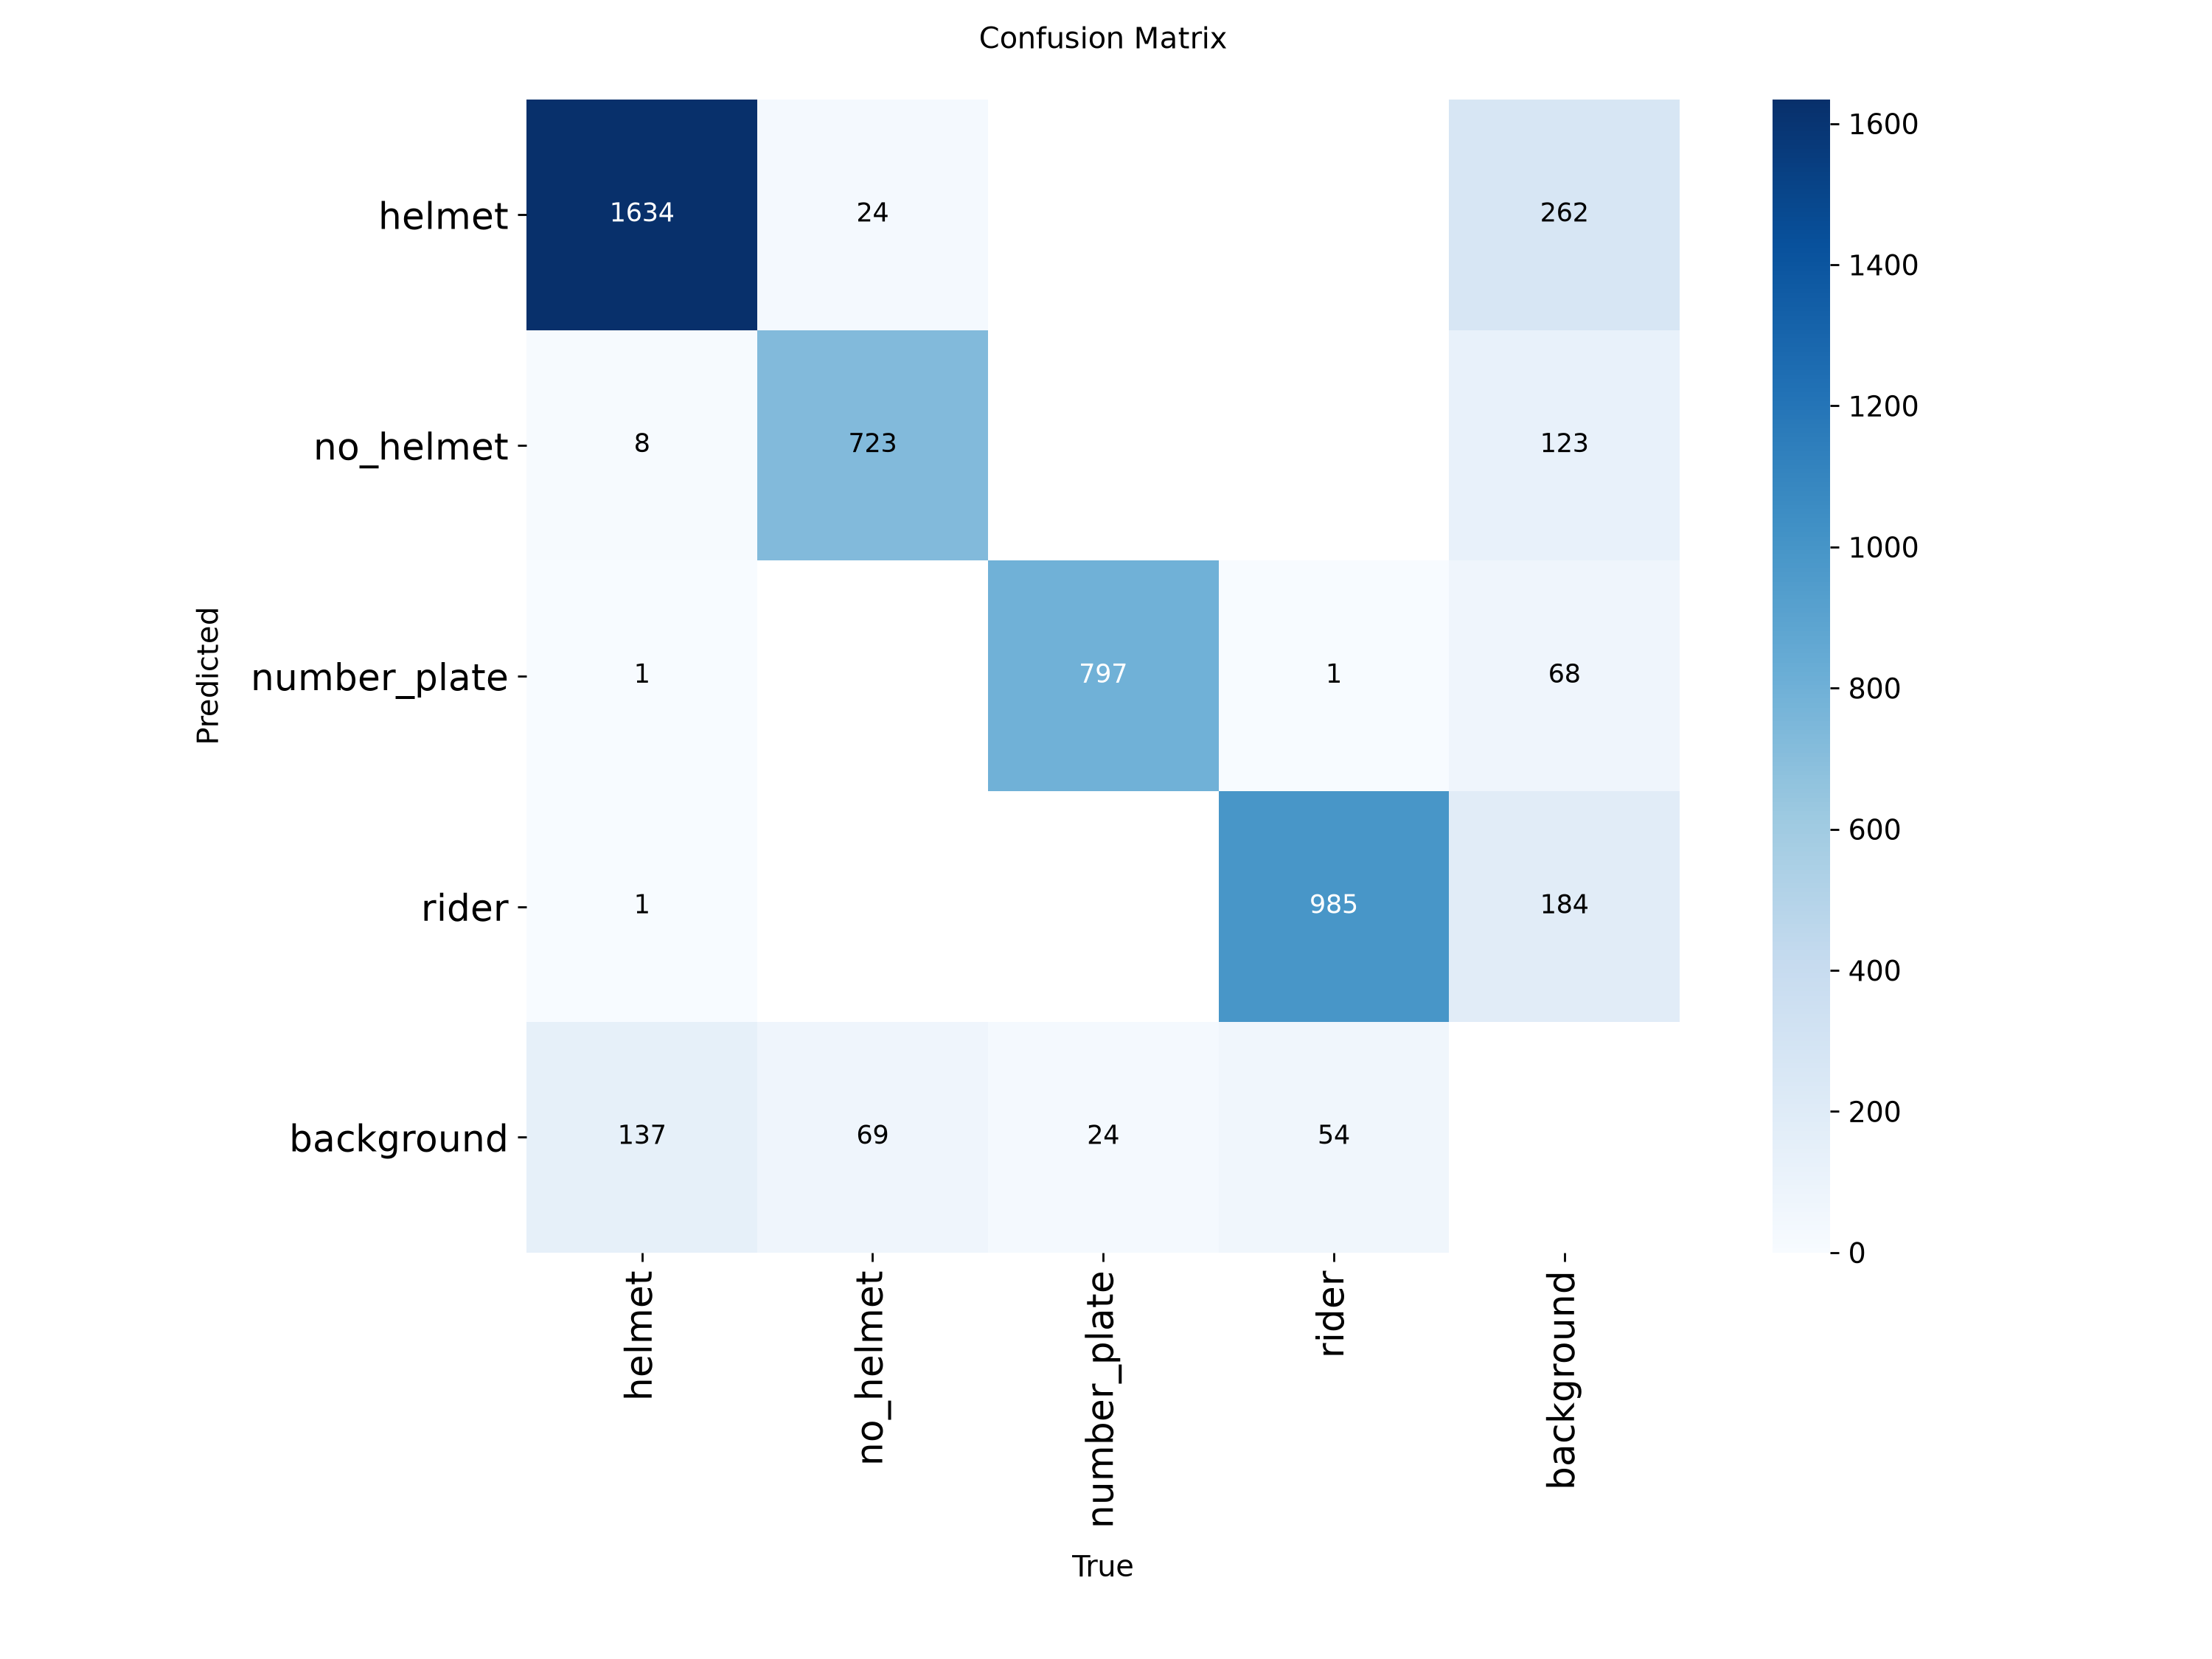

In [8]:
from IPython.display import display, Image

confusion_matrix = evaluation_path / "confusion_matrix.png"

display(Image(filename=str(confusion_matrix)))

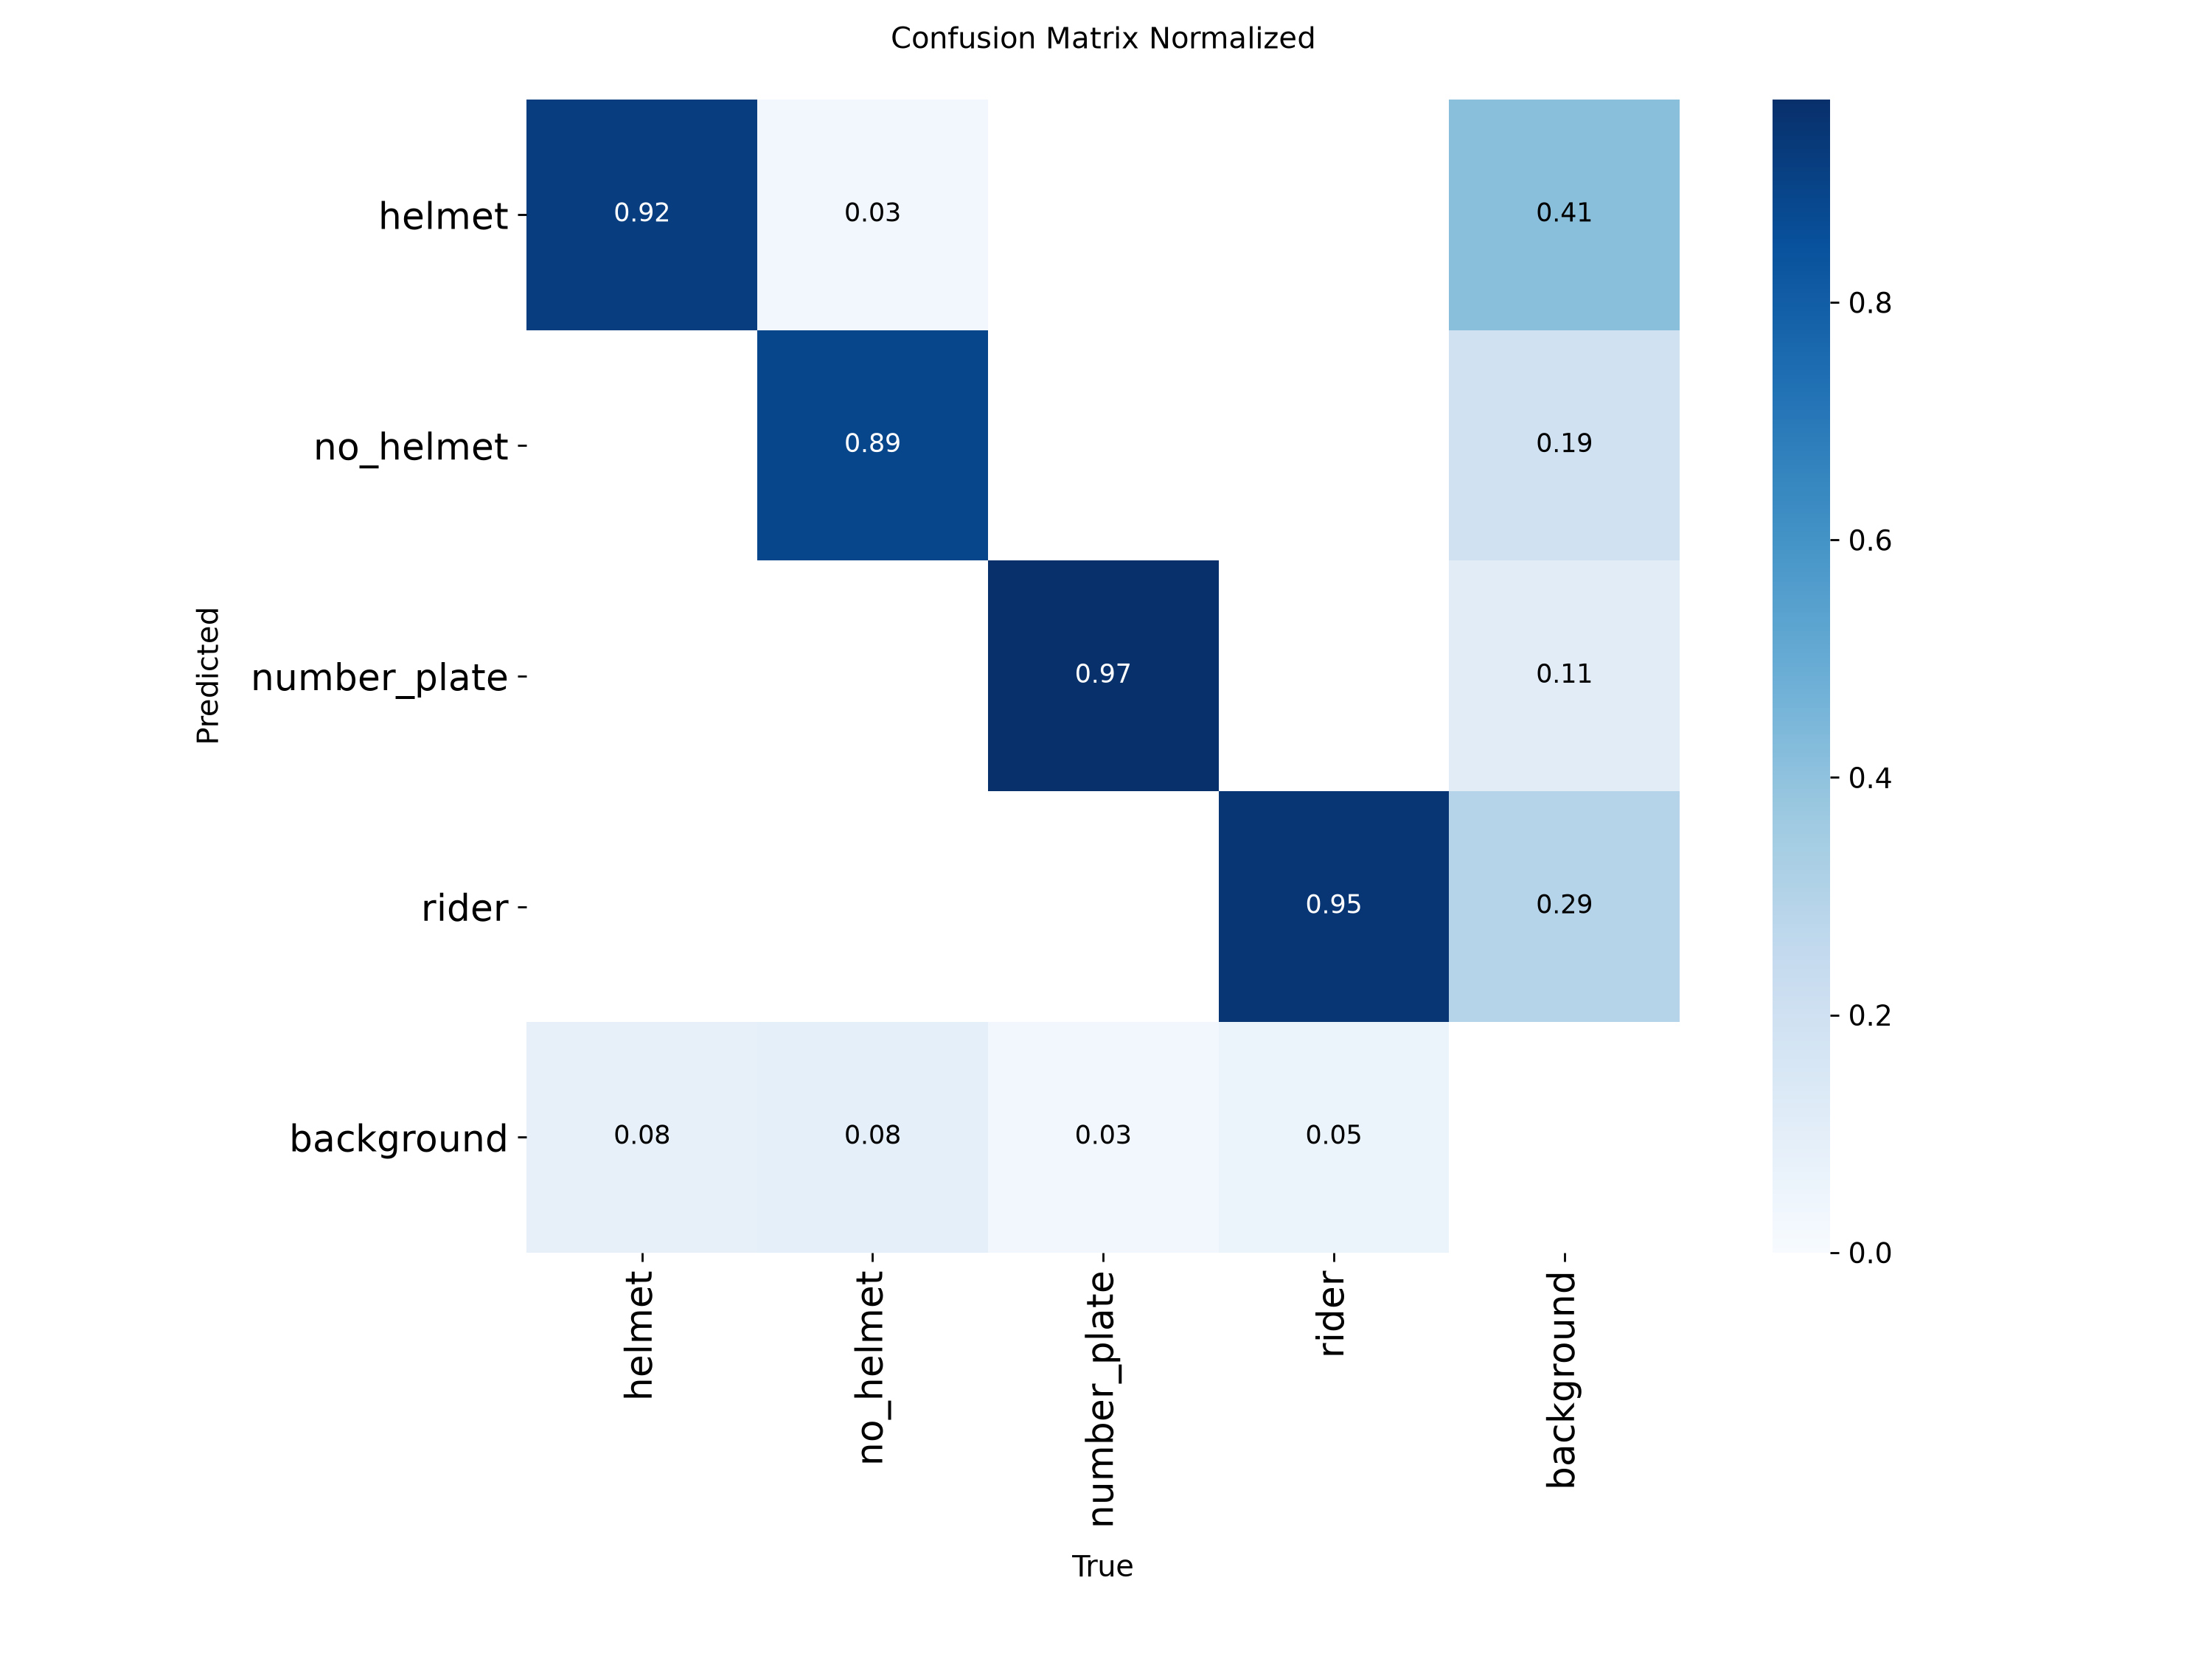

In [9]:
normalized_cm = evaluation_path / "confusion_matrix_normalized.png"

display(Image(filename=str(normalized_cm)))

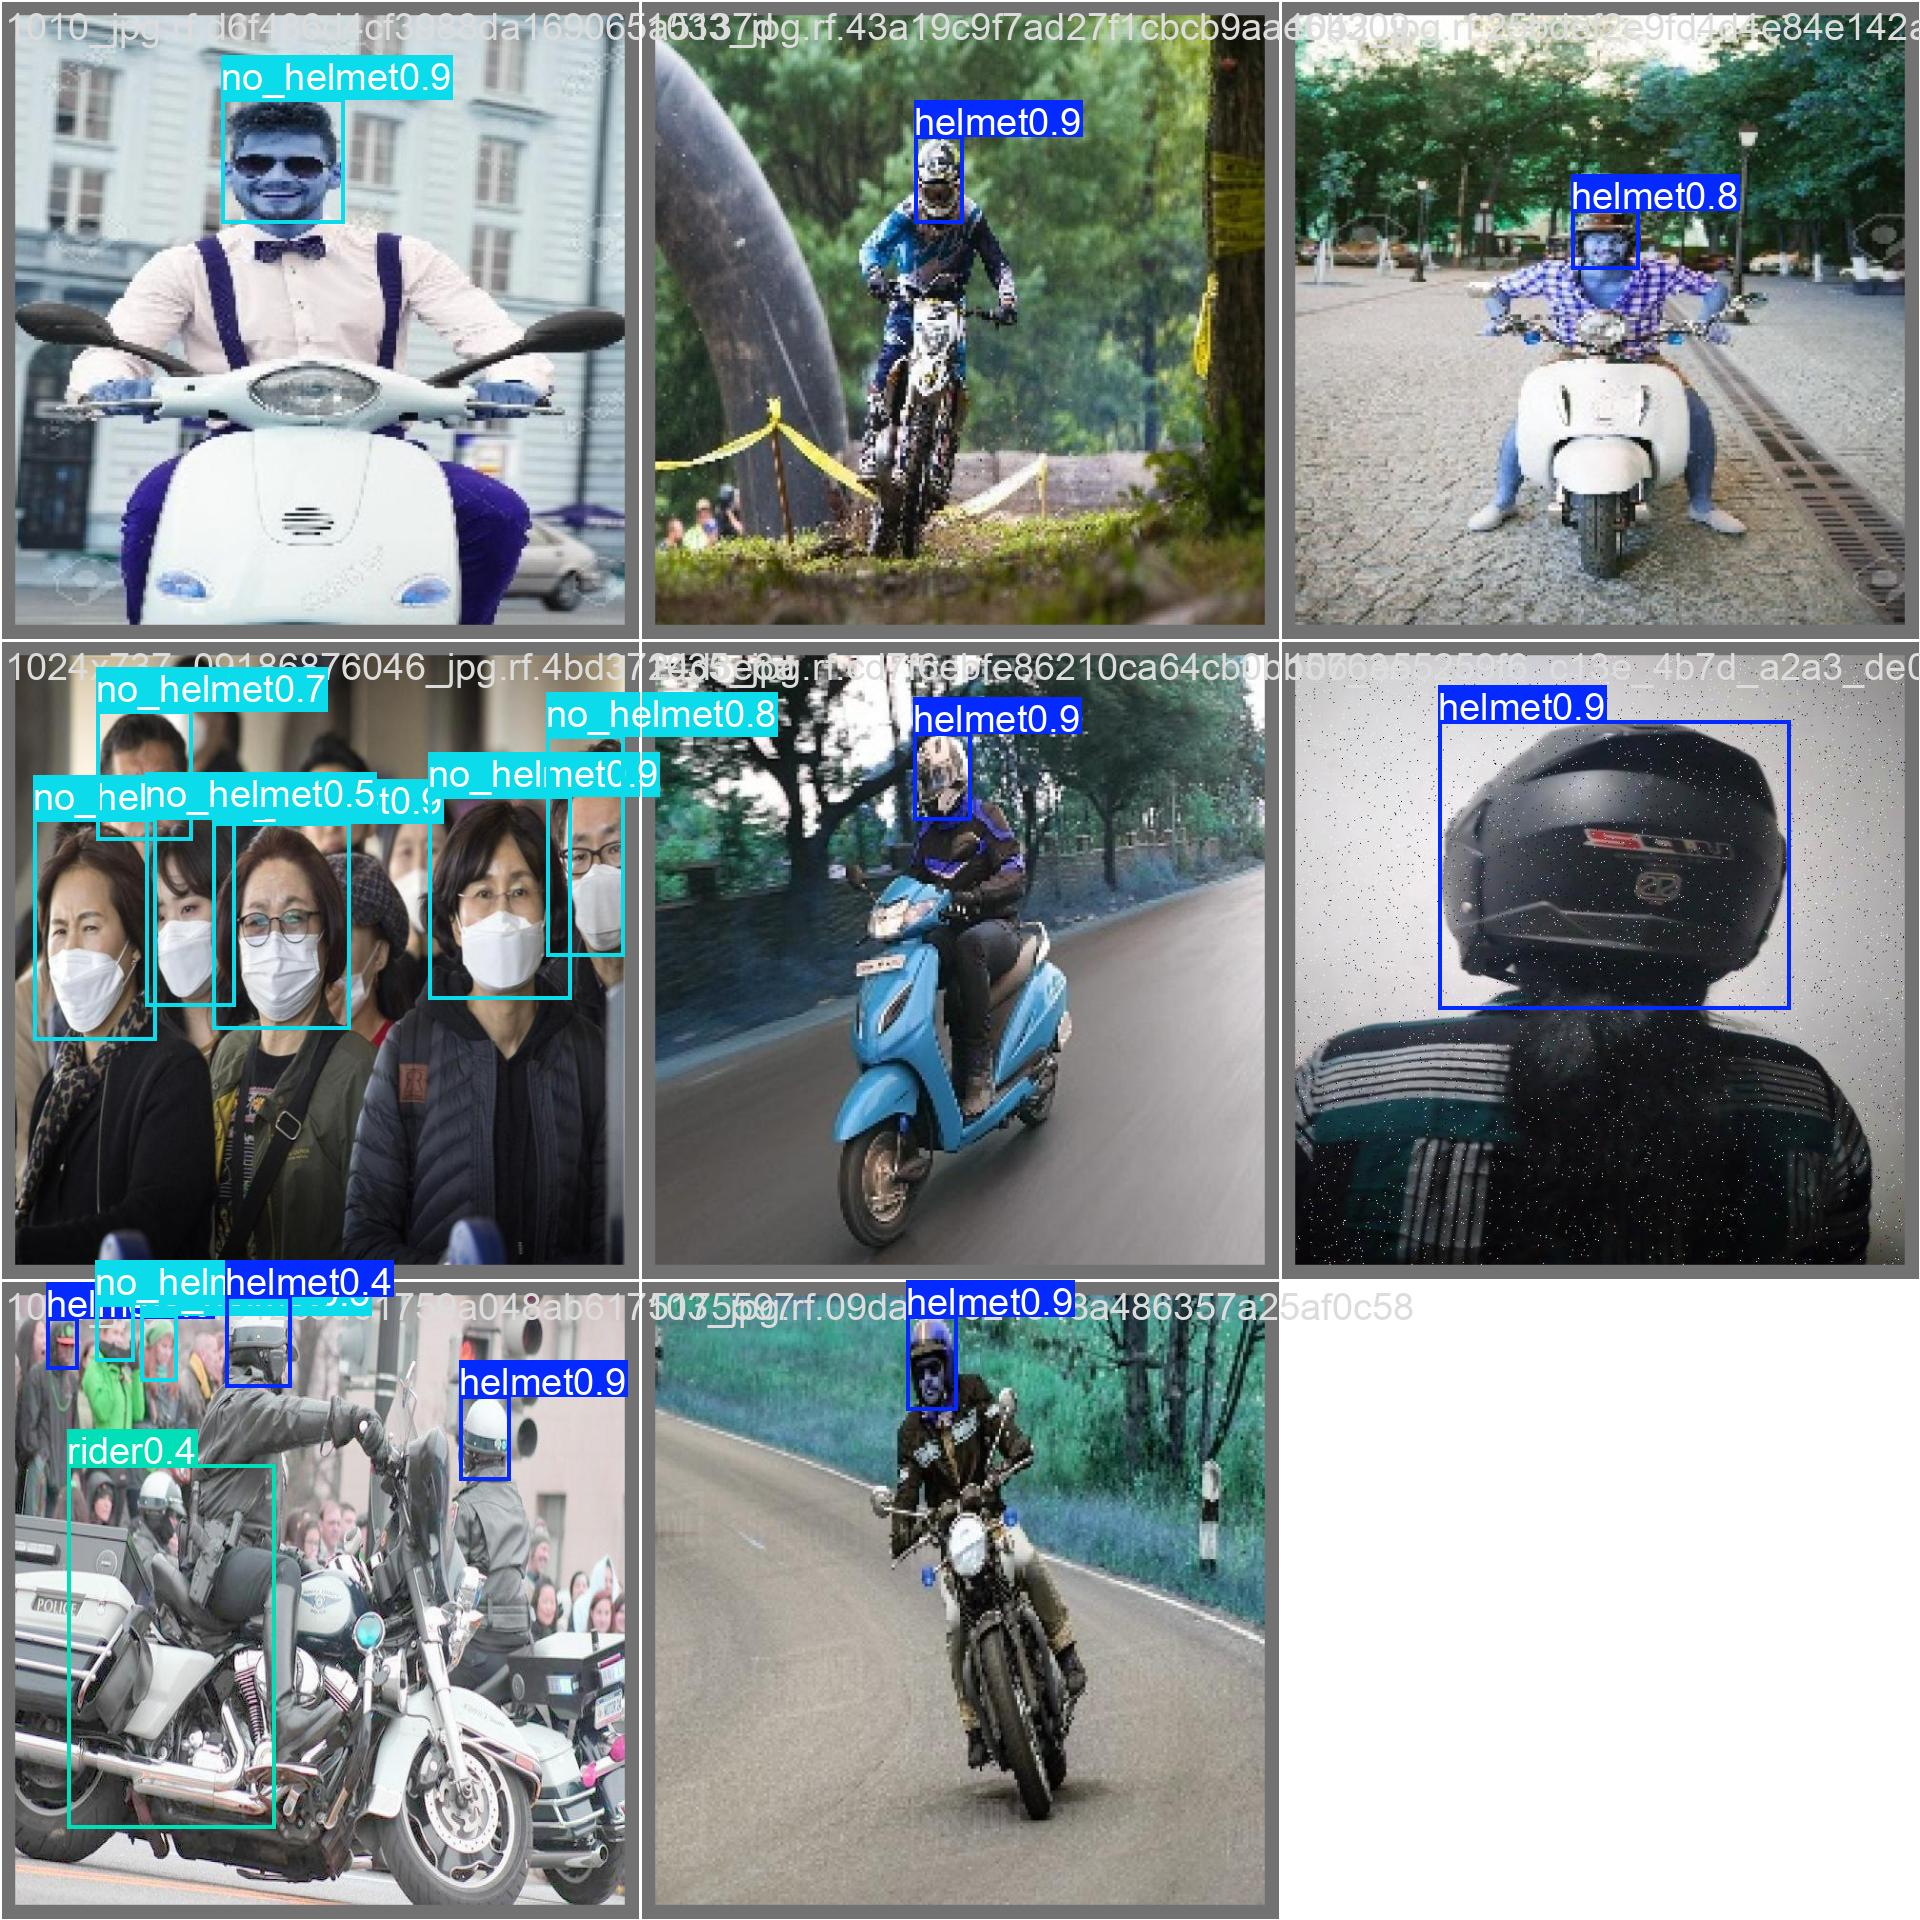

In [10]:
pred_image = evaluation_path / "val_batch0_pred.jpg"

display(Image(filename=str(pred_image)))

Ground Truth:


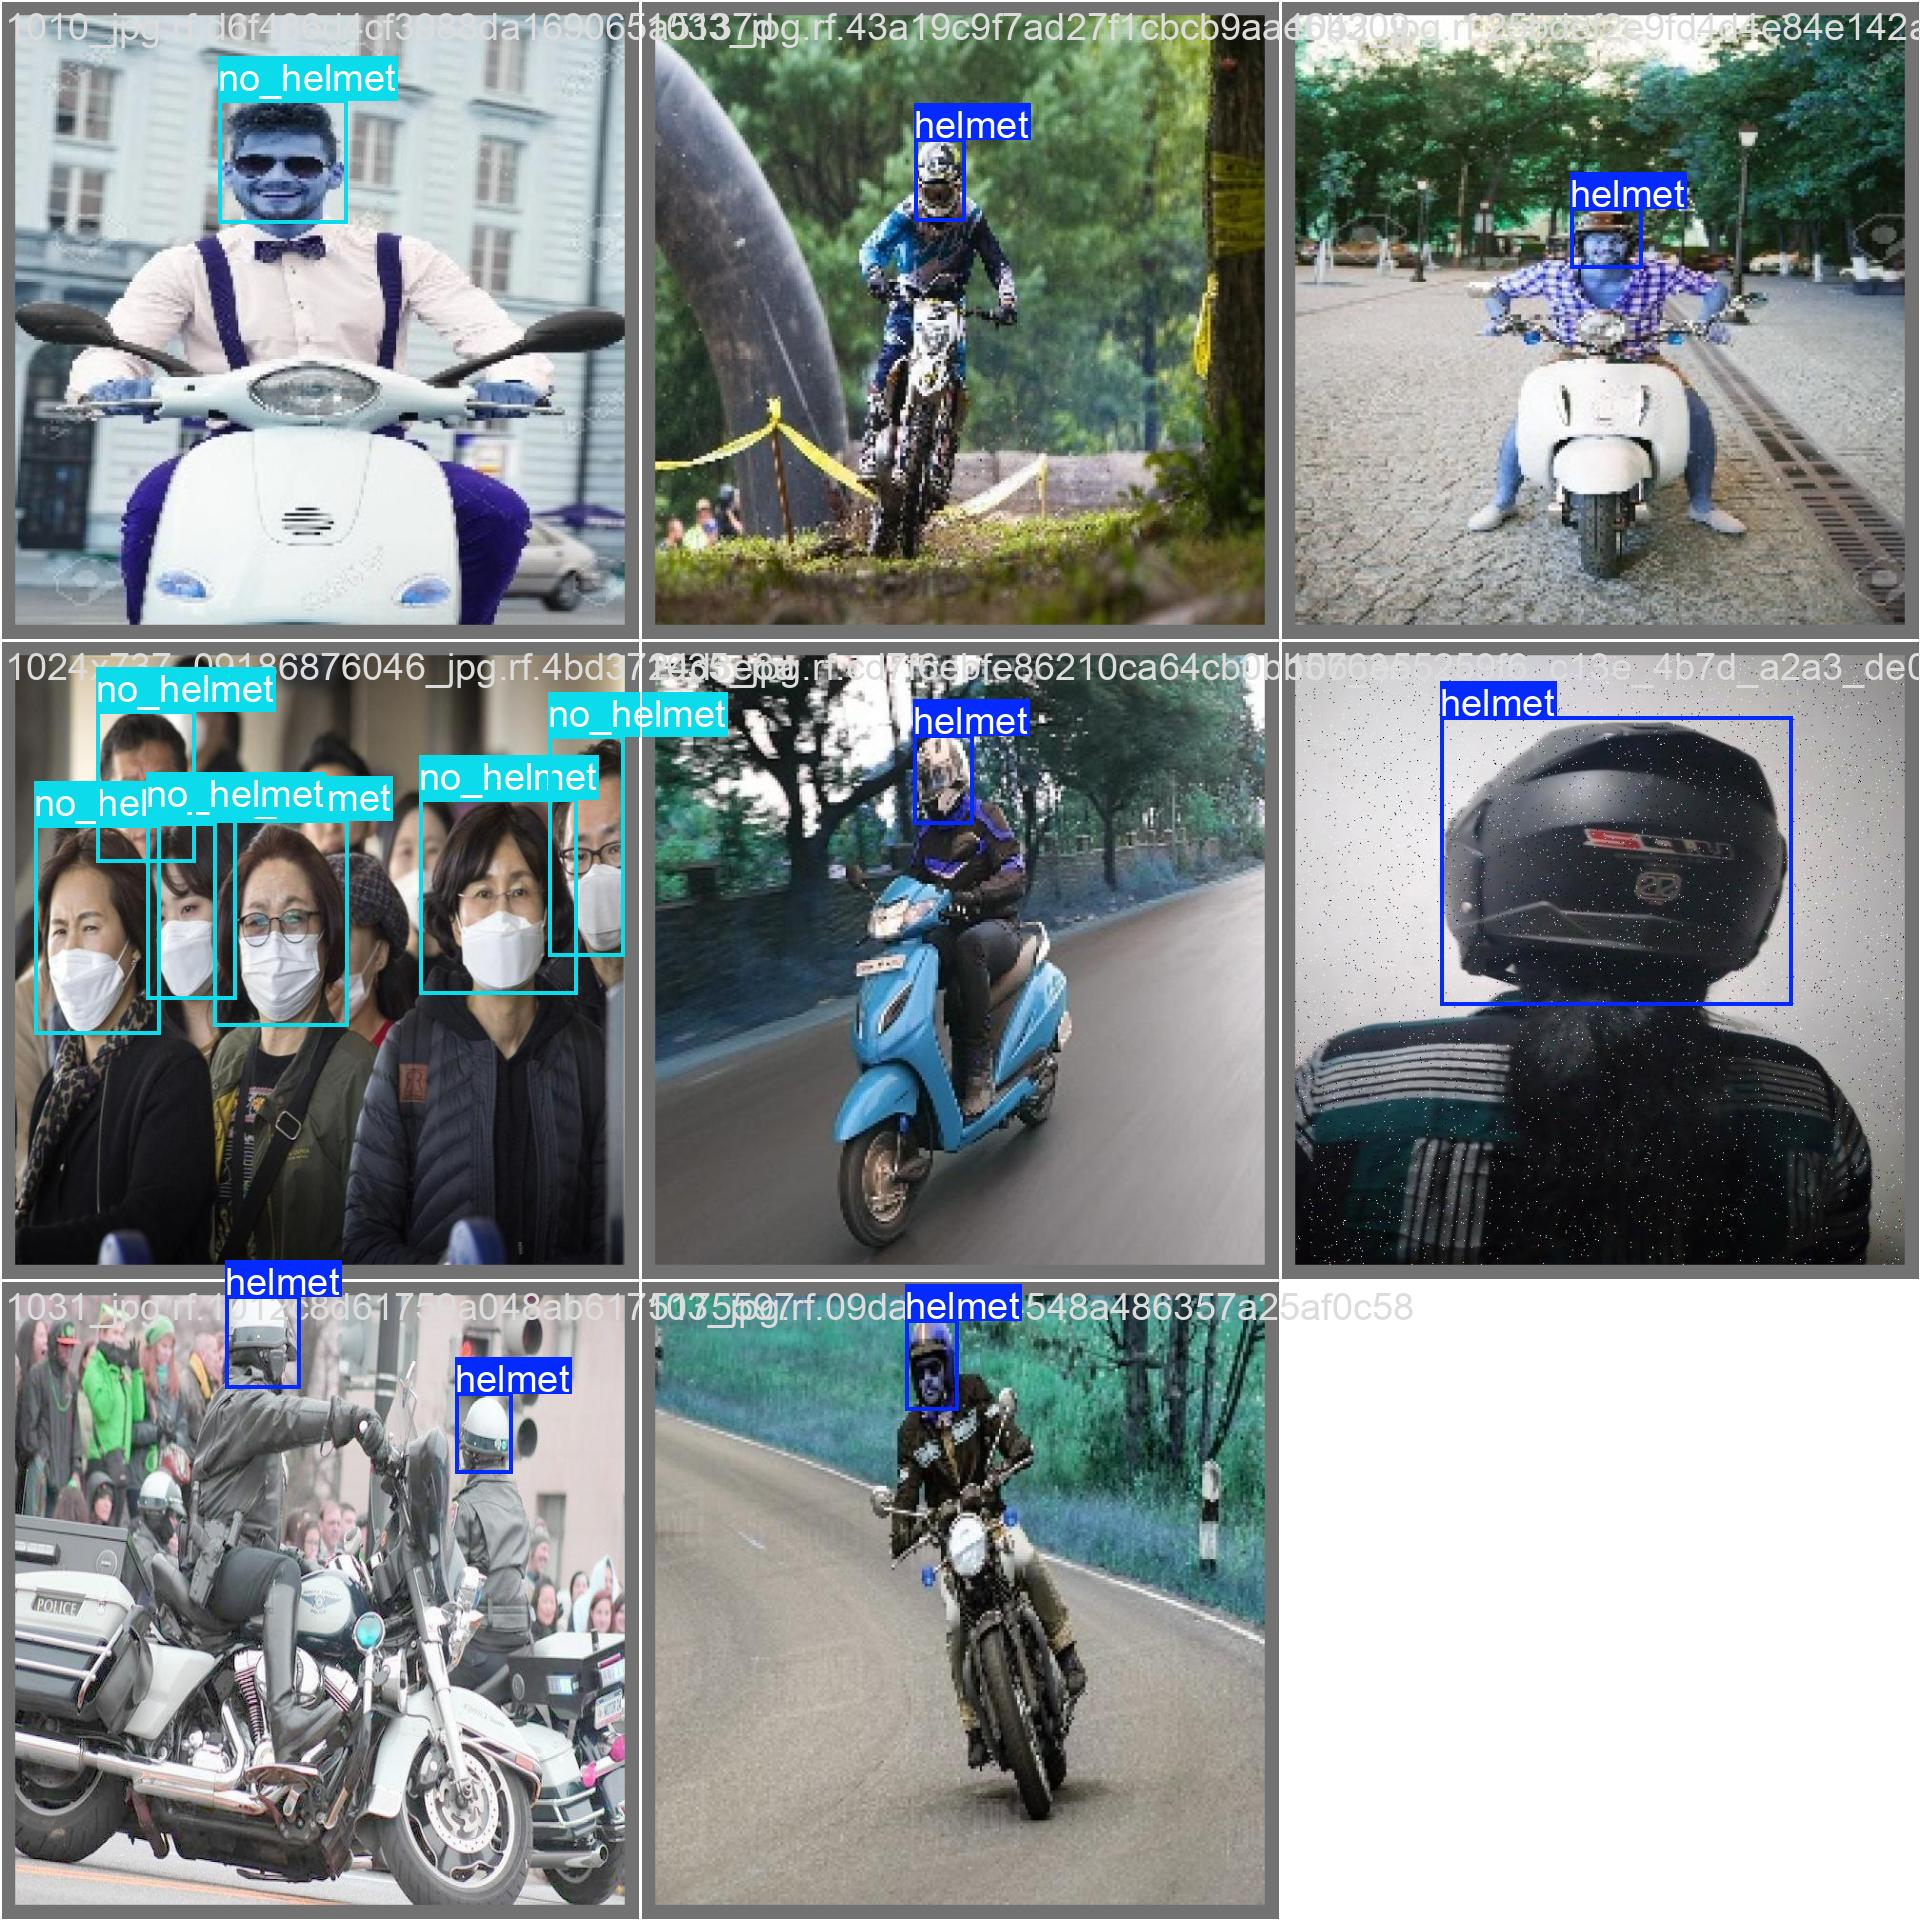

Prediction:


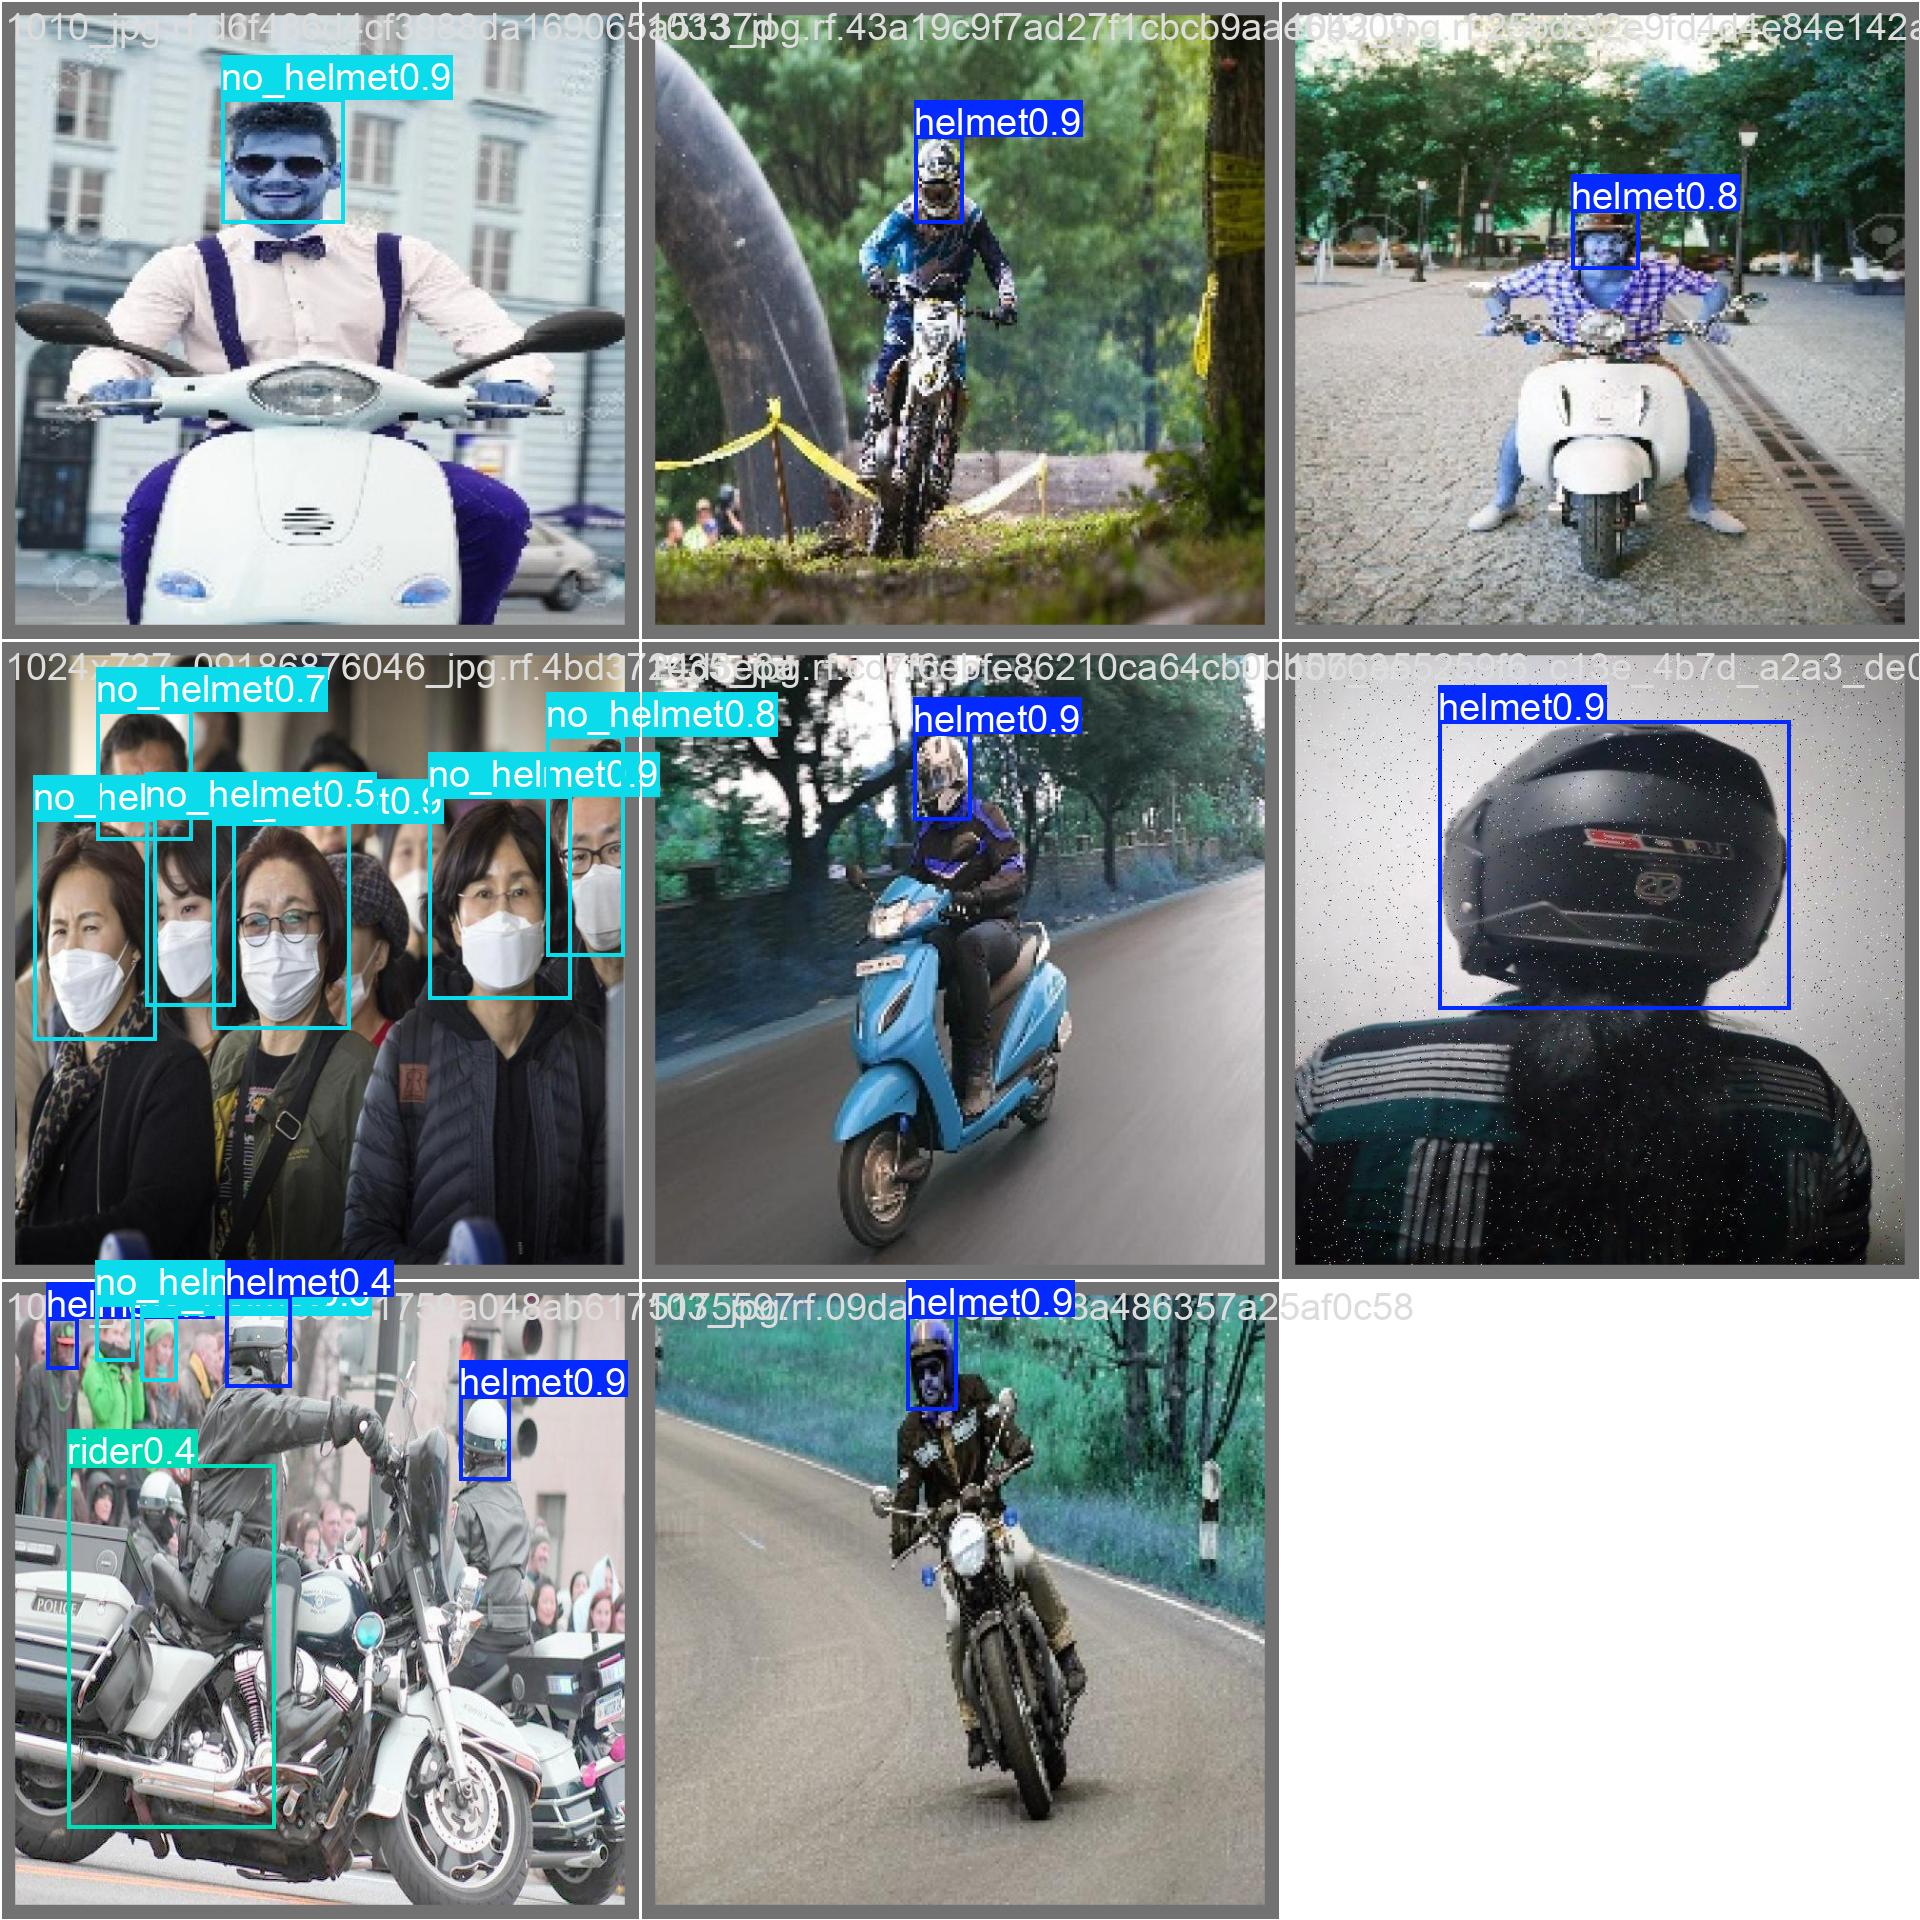

In [11]:
gt_image = evaluation_path / "val_batch0_labels.jpg"
pred_image = evaluation_path / "val_batch0_pred.jpg"

print("Ground Truth:")
display(Image(filename=str(gt_image)))

print("Prediction:")
display(Image(filename=str(pred_image)))

In [12]:
import pandas as pd

evaluation_summary = pd.DataFrame({
    "Class": ["Overall", "Helmet", "No Helmet", "Number Plate", "Rider"],
    "Precision": [
        metrics.box.mp,
        metrics.box.p[0],
        metrics.box.p[1],
        metrics.box.p[2],
        metrics.box.p[3]
    ],
    "Recall": [
        metrics.box.mr,
        metrics.box.r[0],
        metrics.box.r[1],
        metrics.box.r[2],
        metrics.box.r[3]
    ],
    "mAP50": [
        metrics.box.map50,
        metrics.box.ap50[0],
        metrics.box.ap50[1],
        metrics.box.ap50[2],
        metrics.box.ap50[3]
    ],
    "mAP50-95": [
        metrics.box.map,
        metrics.box.ap[0],
        metrics.box.ap[1],
        metrics.box.ap[2],
        metrics.box.ap[3]
    ]
})

display(evaluation_summary.round(3))

evaluation_summary.to_csv(
    evaluation_path / "evaluation_summary.csv",
    index=False
)

print("Evaluation summary saved successfully.")

,Class,Precision,Recall,mAP50,mAP50-95
0,Overall,0.922,0.897,0.950,0.703
1,Helmet,0.923,0.877,0.933,0.656
2,No Helmet,0.913,0.839,0.920,0.637
3,Number Plate,0.955,0.949,0.976,0.715
4,Rider,0.895,0.922,0.969,0.805


Evaluation summary saved successfully.


In [13]:
import shutil

graphs_path = project_path / "results" / "graphs"
predictions_path = project_path / "results" / "predictions"

graphs_path.mkdir(parents=True, exist_ok=True)
predictions_path.mkdir(parents=True, exist_ok=True)

# Graph files
graph_files = [
    "BoxF1_curve.png",
    "BoxP_curve.png",
    "BoxPR_curve.png",
    "BoxR_curve.png",
    "confusion_matrix.png",
    "confusion_matrix_normalized.png"
]

# Prediction / label files
prediction_files = [
    "val_batch0_labels.jpg",
    "val_batch0_pred.jpg",
    "val_batch1_labels.jpg",
    "val_batch1_pred.jpg",
    "val_batch2_labels.jpg",
    "val_batch2_pred.jpg"
]

for file in graph_files:
    source = evaluation_path / file
    if source.exists():
        shutil.copy2(source, graphs_path / file)

for file in prediction_files:
    source = evaluation_path / file
    if source.exists():
        shutil.copy2(source, predictions_path / file)

print("Evaluation files organized successfully!")

Evaluation files organized successfully!


In [14]:


project_path = Path(r"E:\AI_ML PROJECTS\Helmet Detection")

model_path = project_path / "models" / "best.pt"
data_yaml = project_path / "data" / "cleaned" / "helmet_dataset_cleaned" / "data.yaml"

model = YOLO(str(model_path))

train_metrics = model.val(
    data=str(data_yaml),
    split="train",
    imgsz=640,
    batch=8,
    device="cpu",
    plots=True,
    project=str(project_path / "results" / "evaluation"),
    name="train_evaluation",
    exist_ok=True
)

print("Training-set evaluation completed!")

Ultralytics 8.4.149  Python-3.13.12 torch-2.14.0+cpu CPU (11th Gen Intel Core i5-1135G7 @ 2.40GHz)
Model summary (fused): 72 layers, 3,006,428 parameters, 0 gradients, 8.1 GFLOPs
WARNING val: Slow image access detected (ping: 13.78.7 ms, read: 2.42.0 MB/s, size: 65.8 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning E:\AI_ML PROJECTS\Helmet Detection\data\cleaned\helmet_dataset_cleaned\train\labels... 11852 images, 3 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 11852/11852 69.6it/s 2:50<0.0ss
val: New cache created: E:\AI_ML PROJECTS\Helmet Detection\data\cleaned\helmet_dataset_cleaned\train\labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1482/1482 1.3it/s 19:390.7ss
                   all      11852      63671       0.94      0.925       0.97       0.74
                helmet       9330      25716      0.949     